In [1]:
from schedule import Schedule, Slot
from tsn_scheduling_problem import TSNScheduling
from usecase_generator import Usecase
from evaluator import TSNConstraintEvaluator
from tsn_scheduling_problem import TSNScheduling
from env_candidates import TSNCandidateHopEnv
from benchmark_utils import build_network_generator_from_usecase, generate_one_arrival_stream, build_usecase_stream_from_request

In [2]:
problem = TSNScheduling("uc_config.cfg")
instance = problem.import_scheduling_usecase("banana2.json")

In [3]:
import math
import random
import copy
import numpy as np


def generate_episode_trace(
    instance,
    arrivals_per_episode=100,
    lambda_arrival=0.1,
    mu_departure=0.05,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate one shared trace:
      - n_dep per step
      - raw arrival requests per step

    The trace is independent from the policy/benchmark.
    """
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))
    p_dep = 1.0 - math.exp(-mu_departure * dt)

    trace = []
    total_arrivals = 0

    # we need some estimate of active streams to sample n_dep;
    # use current active count of the reference instance and update
    # a simple counter proxy over time
    active_count = len({
        slot.stream_id for slot in instance.schedule
        if slot.stream_id is not None
    })

    while total_arrivals < arrivals_per_episode:
        # departures sampled from current proxy active_count
        n_dep = int(rng_np.binomial(active_count, p_dep)) if active_count > 0 else 0

        sampled_arrivals = int(rng_np.poisson(lambda_arrival))
        remaining = arrivals_per_episode - total_arrivals
        n_arr = min(sampled_arrivals, remaining)

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)
            total_arrivals += 1

        trace.append({
            "n_dep": n_dep,
            "arrivals": arrivals,
        })

        # update proxy active count for future sampling
        active_count = max(0, active_count - n_dep)
        active_count += sum(1 for a in arrivals if a is not None)

    return trace

In [4]:
def run_no_defrag_on_trace(
    instance,
    problem,
    trace,
    seed=42,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0

    for step in trace:
        step_count += 1

        # Departures
        active_stream_ids = sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(step["n_dep"], n_active)

        if n_dep > 0:
            sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
            )

        # Arrivals
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                continue

            result = sched.place_stream_first_fit(
                stream=stream,
                usecase=inst,
                problem=problem,
                port_intervals=port_intervals,
            )

            if result["accepted"]:
                accepted += 1
            else:
                rejected += 1

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
    }

In [5]:
def run_of_ff_on_trace(
    instance,
    problem,
    trace,
    p=15,
    n=3,
    seed=42,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    sched = inst.schedule

    relevant_ports = sorted({slot.port_id for slot in sched if slot.port_id is not None})
    port_intervals = {
        pid: sched._occupied_intervals_on_port(pid, sched.cycle_ns)
        for pid in relevant_ports
    }

    # smaller = older
    stream_age_key = {}
    for sid, stream in enumerate(inst.streams):
        offset = stream.get("offset", 10**9)
        stream_age_key[sid] = (0, offset)

    accepted = 0
    rejected = 0
    total_arrivals = 0
    step_count = 0

    for step in trace:
        step_count += 1

        # Departures
        active_stream_ids = sorted({
            slot.stream_id for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(step["n_dep"], n_active)

        if n_dep > 0:
            sched.delete_streams(
                n_remove=n_dep,
                usecase=inst,
                rng=rng_py,
                port_intervals=port_intervals,
            )

        # Arrivals
        for raw_stream in step["arrivals"]:
            total_arrivals += 1

            if raw_stream is None:
                rejected += 1
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )
            if stream is None:
                rejected += 1
                continue

            result = sched.place_stream_first_fit(
                stream=stream,
                usecase=inst,
                problem=problem,
                port_intervals=port_intervals,
            )

            if result["accepted"]:
                accepted += 1
                new_sid = result["accepted"][-1]
                stream_age_key[new_sid] = (1, total_arrivals)
            else:
                rejected += 1

            sched.oldest_first_first_fit_defrag(
                usecase=inst,
                problem=problem,
                p=p,
                n=n,
                arrival_counter=total_arrivals,
                stream_age_key=stream_age_key,
                port_intervals=port_intervals,
            )

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    return {
        "sbr": sbr,
        "acceptance": acc,
        "steps": step_count,
        "accepted": accepted,
        "rejected": rejected,
        "arrivals": total_arrivals,
    }

In [6]:
import copy
import random
import numpy as np

from stable_baselines3 import DQN
from env import TSNCandidatePathEnv


def run_drl_on_trace(
    model_path,
    instance,
    problem,
    trace,
    seed=42,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
):
    """
    Replay one shared arrival/departure trace using the DRL policy.

    IMPORTANT:
    - Benchmark horizon is controlled by the trace (typically 100 arrivals),
      NOT by env decision_points_per_episode.
    - We use the env only for:
        * candidate generation
        * observations
        * applying reallocation actions
    - We do NOT use the env's internal arrival/departure simulator.

    Trace format:
        [
          {"n_dep": int, "arrivals": [raw_stream_or_None, ...]},
          ...
        ]
    """
    rng_py = random.Random(seed)

    # Build a fresh env, but we will bypass its internal simulator loop.
    env = TSNCandidatePathEnv(
        problem=problem,
        usecase=instance,
        useless_gap_threshold_bytes=useless_gap_threshold_bytes,
        expected_incoming_bytes=expected_incoming_bytes,
        invalid_penalty=invalid_penalty,
        max_candidates=max_candidates,
        max_steps=max_steps,
        max_hops=max_hops,
        init_from_usecase_schedule=init_from_usecase_schedule,
        include_current_offset_candidate=include_current_offset_candidate,
        per_hop_candidate_limit=per_hop_candidate_limit,
        beam_width=beam_width,
        defrag_cycle_penalty=defrag_cycle_penalty,
        reallocation_penalty=reallocation_penalty,
        lambda_arrival=1.0,              # unused here
        mu_departure=0.2,                # unused here
        dt=1.0,                          # unused here
        decision_points_per_episode=10**9,  # effectively disabled for benchmarking
        ed_ed_settings=None,
        top_k_oldest_random=top_k_oldest_random,
        seed=seed,
    )

    model = DQN.load(model_path, env=env)

    # Reset to build internal structures from the initial schedule.
    obs, info = env.reset(seed=seed)

    # After reset(), the training env may already have advanced internally.
    # For benchmarking on a shared trace, overwrite runtime counters and state semantics.
    env.blocked_requests = 0
    env.total_requests = 0
    env.accepted_requests = 0
    env.current_time = 0.0

    env.episode_invalid_moves = 0
    env.episode_violation_sum = 0
    env.episode_decision_points = 0
    env.episode_reallocations = 0
    env.episode_defrag_cycles = 0

    env.decision_active = False
    env.in_defrag_cycle = False
    env.decision_stream_order = []
    env.decision_pointer = 0
    env.current_candidates = []

    # Initial streams are present from the starting schedule.
    # Keep their "arrival times" at 0.0 for age ordering.
    env.stream_arrival_times = {int(sid): 0.0 for sid in env._active_stream_ids()}

    step_count = 0

    for step in trace:
        step_count += 1
        env.current_time += 1.0

        # --------------------------------------------------
        # 1) Departures from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        active_stream_ids = sorted({
            int(slot.stream_id) for slot in sched
            if slot.stream_id is not None
        })
        n_active = len(active_stream_ids)
        n_dep = min(int(step["n_dep"]), n_active)

        if n_dep > 0:
            before_ids = list(active_stream_ids)

            sched.delete_streams(
                n_remove=n_dep,
                usecase=env.usecase,
                rng=rng_py,
                port_intervals=env.port_intervals,
            )

            env._load_state_from_schedule(sched)

            after_ids = env._active_stream_ids()
            removed_ids = env._removed_stream_ids(before_ids, after_ids)
            for sid in removed_ids:
                env.stream_arrival_times.pop(int(sid), None)

            # One decision point occurs because this trace step had departures.
            env.episode_decision_points += 1

            # --------------------------------------------------
            # 2) Let DRL act until STOP or focus list exhausted
            # --------------------------------------------------
            has_decision = env._begin_decision_point()

            if has_decision:
                # We do NOT call env.step(0) because STOP there would trigger
                # the training env's internal simulator advance. Instead, we
                # manually emulate "decision logic only".
                while env.decision_active:
                    obs = env._get_obs()
                    action, _ = model.predict(obs, deterministic=deterministic)
                    action = int(np.asarray(action).item())

                    # Padding -> STOP
                    if action > 0:
                        cand_idx = action - 1
                        if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                            action = 0

                    # STOP: end only the current decision point (no internal sim advance)
                    if action == 0:
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    # Candidate application branch (mirrors env.step logic,
                    # but without calling _finish_decision_point_and_continue()).
                    cand_idx = action - 1
                    chosen_candidate = env.current_candidates[cand_idx]

                    saved_ports = copy.deepcopy(env.port_schedules)
                    saved_offsets = copy.deepcopy(env.stream_offsets)

                    applied = env._apply_stream_move(
                        chosen_candidate.stream_id,
                        chosen_candidate.offsets,
                    )

                    if not applied:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    violation_sum = env._violation_sum()
                    env.episode_violation_sum += int(violation_sum)

                    if violation_sum != 0:
                        env.episode_invalid_moves += 1
                        env.port_schedules = saved_ports
                        env.stream_offsets = saved_offsets
                        env._sync_usecase_schedule()
                        env._sync_evaluator_with_schedule_durations()
                        # Treat as forced stop for benchmark stability
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    # Valid reallocation
                    env._backup_current_as_last_valid()
                    env.episode_reallocations += 1

                    if not env.in_defrag_cycle:
                        env.in_defrag_cycle = True
                        env.episode_defrag_cycles += 1

                    # Move to next focus stream within this decision point
                    env._advance_stream_focus()

                    if env.decision_pointer >= len(env.decision_stream_order):
                        env.decision_active = False
                        env.in_defrag_cycle = False
                        env.current_candidates = []
                        break

                    env.current_candidates = env._candidate_list_for_stream(
                        int(env.focus.stream_id)
                    )

        # --------------------------------------------------
        # 3) Arrivals from shared trace
        # --------------------------------------------------
        env._sync_usecase_schedule()
        sched = env.usecase.schedule

        for raw_stream in step["arrivals"]:
            env.total_requests += 1

            if raw_stream is None:
                env.blocked_requests += 1
                continue

            stream_id = len(env.usecase.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                env.usecase,
                k_paths=1,
            )
            if stream is None:
                env.blocked_requests += 1
                continue

            result = sched.place_stream_first_fit(
                stream=stream,
                usecase=env.usecase,
                problem=env.problem,
                port_intervals=env.port_intervals,
            )

            env._rebuild_runtime_metadata()

            if result.get("accepted", False):
                env.accepted_requests += 1
                env.stream_arrival_times[int(stream_id)] = float(env.current_time)
            else:
                env.blocked_requests += 1

            env._load_state_from_schedule(sched)

    total_arrivals = int(env.total_requests)
    rejections = int(env.blocked_requests)
    accepted = int(env.accepted_requests)

    sbr = rejections / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    result = {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "steps": int(step_count),
        "accepted": accepted,
        "rejected": rejections,
        "arrivals": total_arrivals,
        "decision_points": int(env.episode_decision_points),
        "invalid_moves": int(env.episode_invalid_moves),
        "reallocations": int(env.episode_reallocations),
        "defrag_cycles": int(env.episode_defrag_cycles),
    }

    env.close()
    return result

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [7]:
def benchmark_shared_trace(
    methods,
    instance,
    problem,
    n_episodes=10,
    arrivals_per_episode=100,
    lambda_arrival=0.1,
    mu_departure=0.05,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
    model_path=None,
    p=15,
    n=3,
    max_candidates=5,
    max_steps=500,
    max_hops=None,
    init_from_usecase_schedule=True,
    include_current_offset_candidate=True,
    per_hop_candidate_limit=3,
    beam_width=None,
    defrag_cycle_penalty=0.3,
    reallocation_penalty=0.05,
    invalid_penalty=50.0,
    useless_gap_threshold_bytes=1024,
    expected_incoming_bytes=1024,
    top_k_oldest_random=10,
    deterministic=True,
):
    """
    Flexible shared-trace benchmark.

    methods: tuple/list containing any of:
        - "no_defrag"
        - "of_ff"
        - "drl"

    Returns dict with arrays for requested methods only.
    """

    methods = tuple(methods)
    valid_methods = {"no_defrag", "of_ff", "drl"}
    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid: {valid_methods}")

    if "drl" in methods and model_path is None:
        raise ValueError("model_path must be provided when 'drl' is requested.")

    results = {}

    # initialize storage only for requested methods
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_steps"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_episode_trace(
            instance=instance,
            arrivals_per_episode=arrivals_per_episode,
            lambda_arrival=lambda_arrival,
            mu_departure=mu_departure,
            dt=dt,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        episode_msg = [f"Episode {ep}:"]

        if "no_defrag" in methods:
            res_no = run_no_defrag_on_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                seed=ep_seed,
            )
            results["no_defrag_sbr"].append(res_no["sbr"])
            results["no_defrag_acc"].append(res_no["acceptance"])
            results["no_defrag_steps"].append(res_no["steps"])
            episode_msg.append(f"No-Defrag={res_no['sbr']:.4f}")

        if "of_ff" in methods:
            res_ff = run_of_ff_on_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=p,
                n=n,
                seed=ep_seed,
            )
            results["of_ff_sbr"].append(res_ff["sbr"])
            results["of_ff_acc"].append(res_ff["acceptance"])
            results["of_ff_steps"].append(res_ff["steps"])
            episode_msg.append(f"OF-FF={res_ff['sbr']:.4f}")

        if "drl" in methods:
            res_drl = run_drl_on_trace(
                model_path=model_path,
                instance=instance,
                problem=problem,
                trace=trace,
                seed=ep_seed,
                max_candidates=max_candidates,
                max_steps=max_steps,
                max_hops=max_hops,
                init_from_usecase_schedule=init_from_usecase_schedule,
                include_current_offset_candidate=include_current_offset_candidate,
                per_hop_candidate_limit=per_hop_candidate_limit,
                beam_width=beam_width,
                defrag_cycle_penalty=defrag_cycle_penalty,
                reallocation_penalty=reallocation_penalty,
                invalid_penalty=invalid_penalty,
                useless_gap_threshold_bytes=useless_gap_threshold_bytes,
                expected_incoming_bytes=expected_incoming_bytes,
                top_k_oldest_random=top_k_oldest_random,
                deterministic=deterministic,
            )
            results["drl_sbr"].append(res_drl["sbr"])
            results["drl_acc"].append(res_drl["acceptance"])
            results["drl_steps"].append(res_drl["steps"])
            episode_msg.append(
                f"DRL={res_drl['sbr']:.4f}"
            )

        print(" | ".join(episode_msg))

    # convert lists to numpy arrays
    for k in list(results.keys()):
        dtype = float if ("_sbr" in k or "_acc" in k) else int
        results[k] = np.array(results[k], dtype=dtype)

    return results

In [16]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_sbr_curves(curves, smooth_window=None):
    """
    curves: dict like
    {
        "No-Defrag": sbr_values,
        "Heuristic-A": other_values,
        ...
    }
    """

    styles = [
        {"color": "red", "marker": "x", "linestyle": "-", "markersize": 4},
        {"color": "tab:blue", "marker": "o", "linestyle": "--", "markersize": 4},
        {"color": "tab:green", "marker": "s", "linestyle": "-.", "markersize": 4},
        {"color": "tab:purple", "marker": "+", "linestyle": "-", "markersize": 6},
        {"color": "tab:brown", "marker": "v", "linestyle": "--", "markersize": 4},
        {"color": "orange", "marker": "d", "linestyle": "-", "markersize": 4},
    ]

    plt.figure(figsize=(10, 5))

    for i, (label, values) in enumerate(curves.items()):
        y = np.asarray(values, dtype=float)
        x = np.arange(len(y))

        if smooth_window is not None and smooth_window > 1:
            kernel = np.ones(smooth_window) / smooth_window
            y = np.convolve(y, kernel, mode="same")

        style = styles[i % len(styles)]

        plt.plot(
            x, y,
            label=label,
            linewidth=1.2,
            **style
        )

    plt.ylim(0, 0.4)
    plt.xlabel("Episode", fontsize=12)
    plt.ylabel("Service Blocking Ratio (SBR)", fontsize=12)
    
    n = len(y)
    plt.xlim(0, n - 1)
    plt.margins(x=0)

    ticks = list(range(0, n, 1))
    if (n - 1) not in ticks:
        ticks.append(n - 1)

    # Replace last tick label with n instead of n-1
    labels = [str(t) for t in ticks]
    labels[-1] = str(n)

    plt.xticks(ticks, labels)
    #plt.grid(True, alpha=0.4)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
results2 = benchmark_shared_trace(
    methods=("no_defrag","of_ff",),
    model_path="run_05/best_model.zip",
    instance=instance,
    problem=problem,
    n_episodes=10,
    arrivals_per_episode=100,
    lambda_arrival=1,
    mu_departure=0.6,
    seed=42,
    p=15,
    n=3,
    max_candidates=5,
    max_steps=500,
    deterministic=True,
)

Episode 0: | No-Defrag=0.0700 | OF-FF=0.0700
Episode 1: | No-Defrag=0.0900 | OF-FF=0.0900
Episode 2: | No-Defrag=0.1200 | OF-FF=0.1200
Episode 3: | No-Defrag=0.0300 | OF-FF=0.0300
Episode 4: | No-Defrag=0.0800 | OF-FF=0.0800
Episode 5: | No-Defrag=0.0900 | OF-FF=0.0900
Episode 6: | No-Defrag=0.0900 | OF-FF=0.0900
Episode 7: | No-Defrag=0.0600 | OF-FF=0.0600
Episode 8: | No-Defrag=0.0600 | OF-FF=0.0600
Episode 9: | No-Defrag=0.1000 | OF-FF=0.1000


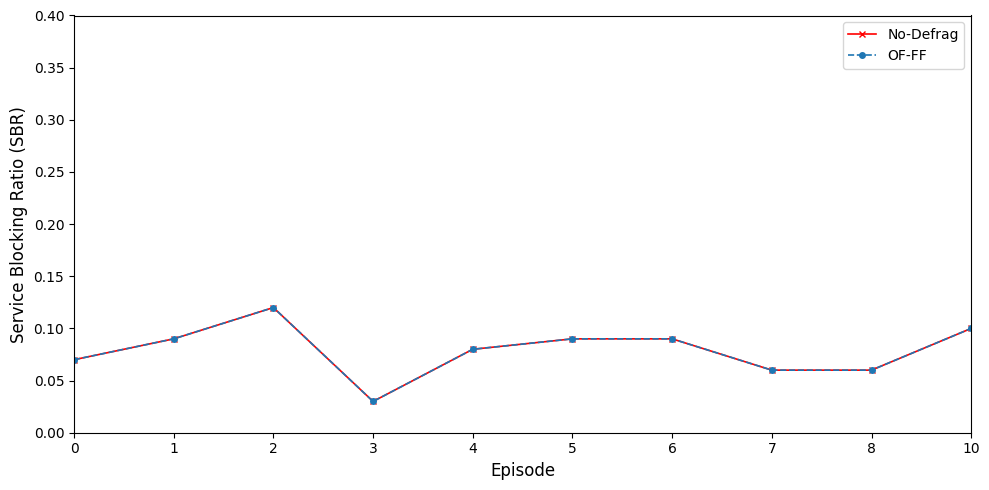

In [18]:
curves = {}

label_map = {
    "no_defrag_sbr": "No-Defrag",
    "of_ff_sbr": "OF-FF",
    "drl_sbr": "DRL",
}

for key, label in label_map.items():
    if key in results2:
        curves[label] = results2[key]

plot_multiple_sbr_curves(curves, smooth_window=None)